# Part 4: Gradient Descent in Code

Model: y = m₁x₁ + m₂x₂ + b, in matrix form ŷ = Xm + b·1
Cost: J(m, b) = (1/n) eᵀe, where e = ŷ − y

This uses the same starting values (m = [-1, 2], b = 1) and learning rate (α = 0.01) as our manual calculation in Part 3, so every printed number can be checked against the handwritten work.


In [6]:
import scipy
print(scipy.__version__)

1.16.3


## 1. Data and initial values
X holds the inputs (one row per data point), y holds the targets. b = [1, 1] is written as b·1, where b = 1 and 1 = [1, 1].

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.differentiate import derivative

X = np.array([[1.0, 3.0],     # data point 1: x1 = 1, x2 = 3
              [4.0, 10.0]])   # data point 2: x1 = 4, x2 = 10
y = np.array([5.0, 6.0])      # targets

m = np.array([-1.0, 2.0])     # initial m = [m1, m2]
b = 1.0                       # initial b (b = [1, 1] is b * 1)
ones = np.ones(len(y))        # the vector 1 = [1, 1]

n = len(y)                    # number of data points = 2
alpha = 0.01                  # learning rate, same as manual
iterations = 3                # one update per group member

## 2. The equation: MSE cost function
J is written as a function of m₁, m₂ and b using matrix multiplication: ŷ = Xm + b·1, e = ŷ − y, J = (1/n)eᵀe.

In [8]:
def cost(m1, m2, b):
    """J = (1/n) * e^T e, written with matrix multiplication."""
    m_vec = np.array([m1, m2])
    y_hat = X @ m_vec + b * ones
    e = y_hat - y
    return (1 / n) * (e @ e)

# Check: at the starting values J should be 61 (same as manual)
print(cost(-1, 2, 1))


61.0


## 3. SciPy derivative function
Partial derivative accepts any equation f and returns its partial derivative with respect to one parameter. It keeps the other parameters fixed, which turns f into a function of one variable, and then derivative estimates the slope at the current value.


In [9]:
def partial_derivative(f, point, index):
    """
    f      : the equation, e.g. cost(m1, m2, b)
    point  : current values [m1, m2, b]
    index  : which parameter to differentiate with respect to
             (0 -> m1, 1 -> m2, 2 -> b)
    """
    def f_one_variable(t):
        # scipy.differentiate.derivative passes arrays of t values,
        # so evaluate f once for each t with the other values fixed
        values = []
        for t_i in np.ravel(t):
            args = list(point)
            args[index] = t_i
            values.append(f(*args))
        return np.reshape(values, np.shape(t))

    result = derivative(f_one_variable, point[index])
    return result.df

# Check: at the starting values this should give 45, 113, 12 (same as manual)
start = [-1.0, 2.0, 1.0]
print(round(partial_derivative(cost, start, 0), 6),
      round(partial_derivative(cost, start, 1), 6),
      round(partial_derivative(cost, start, 2), 6))


45.0 113.0 12.0


## 4. Gradient descent updates
Each iteration shows every step: predictions → error → cost → gradients → update.
The SciPy gradients are printed next to the formulas we derived by hand in Part 2, ∂J/∂m = (2/n)Xᵀe and ∂J/∂b = (2/n)1ᵀe, to show they agree.


In [10]:
m1_history = [m[0]]
m2_history = [m[1]]
b_history = [b]
cost_history = []

for i in range(1, iterations + 1):
    print(f" Iteration {i}")
    print(f"Current m = {m},  b = {b:.6f}")

    # Step 1: predictions  y_hat = X m + b*1
    Xm = X @ m
    y_hat = Xm + b * ones
    print(f"Xm        = {Xm}")
    print(f"y_hat     = Xm + b*1 = {y_hat}")

    # Step 2: error  e = y_hat - y
    e = y_hat - y
    print(f"e         = y_hat - y = {e}")

    # Step 3: cost  J = (1/n) e^T e
    J = (1 / n) * (e @ e)
    cost_history.append(J)
    print(f"J         = (1/{n}) * e^T e = {J:.6f}")

    # Step 4: gradients using the SciPy derivative function
    point = [m[0], m[1], b]
    dJ_dm1 = partial_derivative(cost, point, 0)
    dJ_dm2 = partial_derivative(cost, point, 1)
    dJ_db = partial_derivative(cost, point, 2)
    grad_m = np.array([dJ_dm1, dJ_dm2])
    print(f"SciPy:    dJ/dm = {grad_m.round(6)},  dJ/db = {dJ_db:.6f}")

    # Check against the formulas derived by hand in Part 2
    grad_m_formula = (2 / n) * (X.T @ e)
    grad_b_formula = (2 / n) * (ones @ e)
    print(f"Formula:  dJ/dm = {grad_m_formula.round(6)},  "
          f"dJ/db = {grad_b_formula:.6f}")

    # Step 5: update  m = m - alpha * dJ/dm,  b = b - alpha * dJ/db
    m = m - alpha * grad_m
    b = b - alpha * dJ_db
    print(f"Updated m = m - {alpha} * dJ/dm = {m.round(6)}")
    print(f"Updated b = b - {alpha} * dJ/db = {b:.6f}\n")

    m1_history.append(m[0])
    m2_history.append(m[1])
    b_history.append(b)


 Iteration 1
Current m = [-1.  2.],  b = 1.000000
Xm        = [ 5. 16.]
y_hat     = Xm + b*1 = [ 6. 17.]
e         = y_hat - y = [ 1. 11.]
J         = (1/2) * e^T e = 61.000000
SciPy:    dJ/dm = [ 45. 113.],  dJ/db = 12.000000
Formula:  dJ/dm = [ 45. 113.],  dJ/db = 12.000000
Updated m = m - 0.01 * dJ/dm = [-1.45  0.87]
Updated b = b - 0.01 * dJ/db = 0.880000

 Iteration 2
Current m = [-1.45  0.87],  b = 0.880000
Xm        = [1.16 2.9 ]
y_hat     = Xm + b*1 = [2.04 3.78]
e         = y_hat - y = [-2.96 -2.22]
J         = (1/2) * e^T e = 6.845000
SciPy:    dJ/dm = [-11.84 -31.08],  dJ/db = -5.180000
Formula:  dJ/dm = [-11.84 -31.08],  dJ/db = -5.180000
Updated m = m - 0.01 * dJ/dm = [-1.3316  1.1808]
Updated b = b - 0.01 * dJ/db = 0.931800

 Iteration 3
Current m = [-1.3316  1.1808],  b = 0.931800
Xm        = [2.2108 6.4816]
y_hat     = Xm + b*1 = [3.1426 7.4134]
e         = y_hat - y = [-1.8574  1.4134]
J         = (1/2) * e^T e = 2.723817
SciPy:    dJ/dm = [3.7962 8.5618],  dJ/db = -0.

## 5. Predictions using the final m and b


In [11]:
y_final = X @ m + b * ones
e_final = y_final - y
J_final = (1 / n) * (e_final @ e_final)
cost_history.append(J_final)

print(f"Final m   = {m.round(6)}")
print(f"Final b   = {b:.6f}")
print(f"Predicted = {y_final.round(6)}   (actual y = {y})")
print(f"Final J   = {J_final:.6f}")
print(f"Cost went from {cost_history[0]} to {J_final:.6f}")


Final m   = [-1.369562  1.095182]
Final b   = 0.936240
Predicted = [2.852224 6.409812]   (actual y = [5. 6.])
Final J   = 2.390444
Cost went from 61.0 to 2.390444


## 6a. How m and b change over iterations


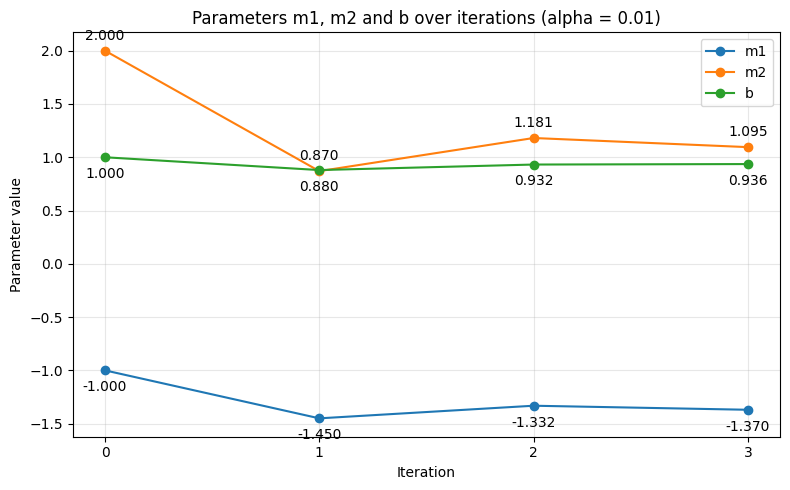

In [12]:
steps = range(iterations + 1)   # 0 = starting values

plt.figure(figsize=(8, 5))
plt.plot(steps, m1_history, marker="o", label="m1")
plt.plot(steps, m2_history, marker="o", label="m2")
plt.plot(steps, b_history, marker="o", label="b")
for k in steps:
    plt.annotate(f"{m1_history[k]:.3f}", (k, m1_history[k]),
                 textcoords="offset points", xytext=(0, -15), ha="center")
    plt.annotate(f"{m2_history[k]:.3f}", (k, m2_history[k]),
                 textcoords="offset points", xytext=(0, 8), ha="center")
    plt.annotate(f"{b_history[k]:.3f}", (k, b_history[k]),
                 textcoords="offset points", xytext=(0, -15), ha="center")
plt.title(f"Parameters m1, m2 and b over iterations (alpha = {alpha})")
plt.xlabel("Iteration")
plt.ylabel("Parameter value")
plt.xticks(list(steps))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


m₂ changes the most because x₂ (3 and 10) is larger than x₁, so its gradient is larger. m₂ zig-zags (2 → 0.87 → 1.18 → 1.10) because the first step overshot, but the swings shrink, so it is converging. b barely changes.


## 6b. How the error changes over iterations


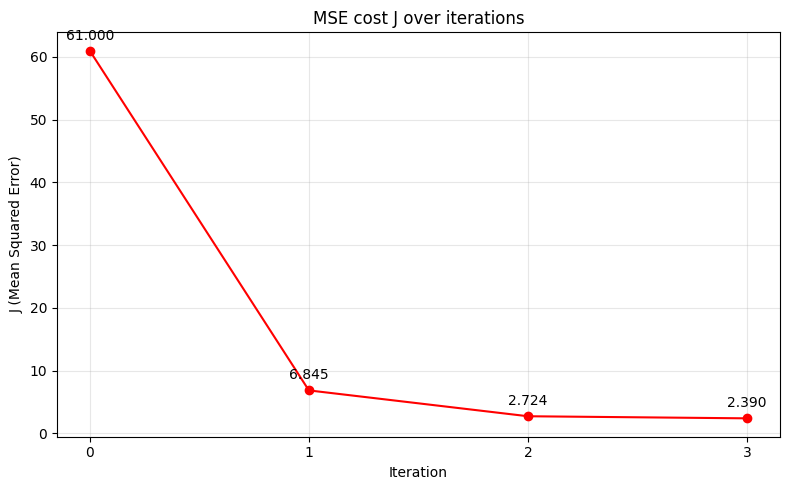

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(steps, cost_history, marker="o", color="red")
for k in steps:
    plt.annotate(f"{cost_history[k]:.3f}", (k, cost_history[k]),
                 textcoords="offset points", xytext=(0, 8), ha="center")
plt.title("MSE cost J over iterations")
plt.xlabel("Iteration")
plt.ylabel("J (Mean Squared Error)")
plt.xticks(list(steps))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


The error falls every iteration (61 → 6.845 → 2.724 → 2.390), so gradient descent is moving m and b in a direction that reduces the error. The biggest drop is in the first update, when the gradient is largest. The drops get smaller as we get closer to the minimum. These values match our manual calculations in Part 3.
